In [1]:
from pathlib import Path
import math
import random
import shutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps, ImageDraw
from ultralytics import YOLO

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


In [ ]:
# path
DATA_DIR = Path("data")
FOCUSED_DIR = Path("data_focused_v2")
CLEAN_DIR = Path("data_cleaned_v2")
BLUR_REVIEW_DIR = Path("blur_review_v2")
FOCUS_REVIEW_DIR = Path("focus_review_v2")

FOLDERS = ["trainA", "trainB", "testA", "testB"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# YOLO DETECTION 
# s lebih kuat daripada n, tetapi inferensi lebih lambat.
YOLO_WEIGHTS = "yolov8s.pt"

# COCO class IDs: horse=17, zebra=22.
# Domain A = horse, Domain B = zebra.
TARGET_CLASS_BY_FOLDER = {
    "trainA": 17,
    "testA": 17,
    "trainB": 22,
    "testB": 22,
}

DETECTION_CONF = 0.08       # rendah agar objek kecil punya peluang terdeteksi
DETECTION_IMGSZ = 1280      # lebih besar = detail inferensi lebih tinggi, lebih lambat
USE_TTA = False             # ubah True jika ingin test-time augmentation (lebih lambat)
MIN_OBJECT_AREA_PCT = 25.0

# Tiled inference dipakai jika foto cukup besar.
USE_TILED_DETECTION = True
TILE_SIZE = 768
TILE_OVERLAP = 0.25
TILE_IMGSZ = 1024
NMS_IOU_THRESHOLD = 0.55

# Padding di sekeliling bounding box objek.
CROP_PADDING = 0.25

# BLUR / MODEL INPUT 
BLUR_THRESHOLD = 100.0      
MIN_BLUR_ROI_SIZE = 16      

IMAGE_SIZE = 256
BATCH_SIZE = 1

print("Konfigurasi siap.")


Konfigurasi siap.


In [ ]:
# Load model pretrained COCO.
detector = YOLO(YOLO_WEIGHTS)
print("YOLO siap:", YOLO_WEIGHTS)


YOLO siap: yolov8s.pt


## 1. Fungsi deteksi objek yang lebih kuat

- `trainA/testA` hanya mencari horse.
- `trainB/testB` hanya mencari zebra.
- Foto besar dipindai penuh dan juga per-tile yang saling overlap agar objek kecil tidak terlalu mengecil saat inferensi.
- Hasil tile dikembalikan ke koordinat gambar asli, lalu kotak duplikat disaring dengan NMS.

In [4]:
def tile_starts(length, tile_size, overlap):
    """Titik awal tile yang mencakup seluruh sisi gambar."""
    if length <= tile_size:
        return [0]

    step = max(1, int(tile_size * (1 - overlap)))
    starts = list(range(0, length - tile_size + 1, step))
    last = length - tile_size
    if starts[-1] != last:
        starts.append(last)
    return starts


def predict_boxes(image_bgr, class_id, imgsz):
    """Keluarkan list deteksi [x1, y1, x2, y2, confidence]."""
    results = detector.predict(
        source=image_bgr,
        conf=DETECTION_CONF,
        classes=[class_id],
        imgsz=imgsz,
        iou=0.50,
        augment=USE_TTA,
        verbose=False
    )

    result = results[0]
    if result.boxes is None or len(result.boxes) == 0:
        return []

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()

    detections = []
    for box, score in zip(boxes, scores):
        detections.append([
            float(box[0]), float(box[1]),
            float(box[2]), float(box[3]),
            float(score)
        ])
    return detections


def box_iou_xyxy(a, b):
    """Intersection over Union untuk dua box format xyxy."""
    ix1 = max(a[0], b[0])
    iy1 = max(a[1], b[1])
    ix2 = min(a[2], b[2])
    iy2 = min(a[3], b[3])
    iw = max(0.0, ix2 - ix1)
    ih = max(0.0, iy2 - iy1)
    intersection = iw * ih
    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def nms_detections(detections, iou_threshold=NMS_IOU_THRESHOLD):
    """Buang box duplikat hasil full-image dan tiled inference."""
    if not detections:
        return []

    detections = sorted(detections, key=lambda d: d[4], reverse=True)
    kept = []
    while detections:
        best = detections.pop(0)
        kept.append(best)
        detections = [
            d for d in detections
            if box_iou_xyxy(best[:4], d[:4]) < iou_threshold
        ]
    return kept


def detect_objects(image, class_id):
    """Deteksi di seluruh gambar dan pada tile jika gambar cukup besar."""
    image_rgb = np.array(image.convert("RGB"))
    image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
    height, width = image_bgr.shape[:2]

    detections = predict_boxes(image_bgr, class_id, DETECTION_IMGSZ)

    if USE_TILED_DETECTION and max(width, height) > TILE_SIZE:
        xs = tile_starts(width, TILE_SIZE, TILE_OVERLAP)
        ys = tile_starts(height, TILE_SIZE, TILE_OVERLAP)

        for y0 in ys:
            for x0 in xs:
                tile = image_bgr[
                    y0:min(y0 + TILE_SIZE, height),
                    x0:min(x0 + TILE_SIZE, width)
                ]
                if tile.size == 0:
                    continue

                tile_detections = predict_boxes(
                    tile, class_id, TILE_IMGSZ
                )

                # Geser koordinat lokal tile ke koordinat gambar asli.
                for d in tile_detections:
                    detections.append([
                        d[0] + x0, d[1] + y0,
                        d[2] + x0, d[3] + y0,
                        d[4]
                    ])

    # Batasi box ke batas gambar.
    for d in detections:
        d[0] = float(np.clip(d[0], 0, width - 1))
        d[1] = float(np.clip(d[1], 0, height - 1))
        d[2] = float(np.clip(d[2], 0, width))
        d[3] = float(np.clip(d[3], 0, height))

    detections = [
        d for d in detections if d[2] > d[0] and d[3] > d[1]
    ]
    return nms_detections(detections)


## 2. Crop mengikuti objek (bukan rasio seluruh foto)

**Perubahan penting dari versi sebelumnya:** fungsi lama memaksa crop mengikuti rasio seluruh foto. Pada foto landscape, crop menjadi sangat lebar dan hewan tetap terlihat kecil. Fungsi baru mengambil bounding box objek + padding. Piksel tidak diregangkan; rasio crop mengikuti area objek.

Jika ada beberapa hewan yang terdeteksi, box digabung agar semua objek target tetap tercakup. Jika deteksi tidak ada, gambar disimpan utuh dan diberi status `no_detection` untuk pemeriksaan manual.

In [5]:
def crop_around_object(image, box, padding=CROP_PADDING):
    """Crop ketat di sekitar box + padding, tanpa mengubah rasio piksel."""
    image_w, image_h = image.size
    x1, y1, x2, y2 = [float(v) for v in box]

    box_w = max(1.0, x2 - x1)
    box_h = max(1.0, y2 - y1)
    pad_x = box_w * padding
    pad_y = box_h * padding

    left = max(0, int(math.floor(x1 - pad_x)))
    top = max(0, int(math.floor(y1 - pad_y)))
    right = min(image_w, int(math.ceil(x2 + pad_x)))
    bottom = min(image_h, int(math.ceil(y2 + pad_y)))

    # Jika box terlalu dekat tepi, crop tetap dibatasi dalam gambar.
    if right <= left or bottom <= top:
        return image.copy(), (0, 0, image_w, image_h)

    return image.crop((left, top, right, bottom)), (left, top, right, bottom)


def detect_and_focus(image_path, detector_class_id):
    """
    Jika objek sudah cukup besar, pertahankan gambar asli.
    Jika objek terlalu kecil, crop mengikuti bounding box.
    """

    with Image.open(image_path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")

    original_w, original_h = image.size

    detections = detect_objects(image, detector_class_id)

    # Jika objek tidak terdeteksi, simpan gambar asli
    # untuk pemeriksaan manual.
    if not detections:
        return (
            image.copy(), "no_detection", 0, None, None,
            "no_crop", (0, 0, original_w, original_h),
            original_w, original_h
        )

    # Pilih deteksi dengan confidence yang relevan.
    max_conf = max(d[4] for d in detections)

    selected = [
        d for d in detections
        if d[4] >= max_conf * 0.50
    ]

    # Gabungkan bounding box objek yang terdeteksi.
    x1 = min(d[0] for d in selected)
    y1 = min(d[1] for d in selected)
    x2 = max(d[2] for d in selected)
    y2 = max(d[3] for d in selected)

    union_box = (x1, y1, x2, y2)

    # Hitung persentase luas objek.
    object_area = max(0, x2 - x1) * max(0, y2 - y1)
    original_area = original_w * original_h

    object_area_pct = (
        object_area / original_area
    ) * 100

    # Jika objek sudah cukup besar, tidak perlu crop.
    if object_area_pct >= MIN_OBJECT_AREA_PCT:

        focused = image.copy()

        crop_box = (
            0, 0, original_w, original_h
        )

        crop_action = "kept_original"

    else:
        # Jika objek masih kecil, lakukan crop.
        focused, crop_box = crop_around_object(
            image,
            union_box,
            padding=CROP_PADDING
        )

        crop_action = "cropped"

    return (
        focused,
        "detected",
        len(selected),
        union_box,
        float(max_conf),
        crop_action,
        crop_box,
        original_w,
        original_h
    )


## 3. Jalankan object-focused cropping

Output disimpan di `data_focused_v2/`. `focus_report_v2.csv` mencatat confidence, ukuran box objek, proporsi area objek, dan rasio area crop terhadap gambar asli. Nilai ini berguna untuk menemukan gambar yang masih belum fokus.

In [6]:
focus_records = []

for folder in FOLDERS:
    folder_path = DATA_DIR / folder
    if not folder_path.exists():
        print(f"Folder tidak ditemukan: {folder_path}")
        continue

    target_class_id = TARGET_CLASS_BY_FOLDER[folder]
    print(f"Memproses {folder} | target class ID: {target_class_id}")

    for image_path in folder_path.rglob("*"):
        if not image_path.is_file() or image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        relative_path = image_path.relative_to(DATA_DIR)
        output_path = FOCUSED_DIR / relative_path
        output_path.parent.mkdir(parents=True, exist_ok=True)

        try:
            ( focused_image, status, detection_count, 
             bbox, max_conf, crop_action, crop_box, original_w, original_h
            ) = detect_and_focus(image_path, target_class_id)

            focused_image.save(output_path)

            x1, y1, x2, y2 = bbox if bbox is not None else (None, None, None, None)
            object_area = (
                max(0, x2 - x1) * max(0, y2 - y1)
                if bbox is not None else 0
            )
            crop_area = (
                (crop_box[2] - crop_box[0]) * (crop_box[3] - crop_box[1])
            )
            original_area = original_w * original_h

            focus_records.append({
                "folder": folder,
                "filename": image_path.name,
                "source_path": str(image_path),
                "focused_path": str(output_path),
                "focus_status": status,
                "detection_count": detection_count,
                "max_confidence": max_conf,
                "bbox_x1": x1, "bbox_y1": y1,
                "bbox_x2": x2, "bbox_y2": y2,
                "object_area_pct": 100 * object_area / original_area,
                "crop_area_pct": 100 * crop_area / original_area,
                "original_width": original_w,
                "original_height": original_h,
                "crop_action": crop_action,
                "crop_width": crop_box[2] - crop_box[0],
                "crop_height": crop_box[3] - crop_box[1]
            })

        except Exception as error:
            print(f"Gagal memproses {image_path}: {error}")
            focus_records.append({
                "folder": folder,
                "filename": image_path.name,
                "source_path": str(image_path),
                "focused_path": None,
                "focus_status": "unreadable",
                "detection_count": 0,
                "max_confidence": None,
                "bbox_x1": None, "bbox_y1": None,
                "bbox_x2": None, "bbox_y2": None,
                "object_area_pct": None,
                "crop_area_pct": None,
                "crop_action": "unreadable",
                "original_width": None, "original_height": None,
                "crop_width": None, "crop_height": None
            })

focus_df = pd.DataFrame(focus_records)
focus_df.to_csv("focus_report_v2.csv", index=False)

if not focus_df.empty:
    print("\nRingkasan deteksi:")
    print(focus_df.groupby(["folder", "focus_status"]).size())
    print("\nStatistik area crop (% dari foto asli):")
    print(focus_df.groupby("folder")["crop_area_pct"].describe())

print("Laporan: focus_report_v2.csv")
print("Hasil crop:", FOCUSED_DIR)


Memproses trainA | target class ID: 17
Memproses trainB | target class ID: 22
Memproses testA | target class ID: 17
Memproses testB | target class ID: 22

Ringkasan deteksi:
folder  focus_status
testA   detected          89
        no_detection      31
testB   detected         118
        no_detection      22
trainA  detected         819
        no_detection     248
trainB  detected        1110
        no_detection     224
dtype: int64

Statistik area crop (% dari foto asli):
         count       mean        std       min        25%         50%    75%  \
folder                                                                         
testA    120.0  63.552068  38.699215  1.017761  25.170135  100.000000  100.0   
testB    140.0  77.869481  31.597525  5.026245  48.185349  100.000000  100.0   
trainA  1067.0  61.519671  37.512535  0.123596  26.644135   51.098633  100.0   
trainB  1334.0  76.860993  31.601446  0.915527  46.173096  100.000000  100.0   

          max  
folder         
testA 

## 4. Audit visual: original dengan bounding box vs hasil crop

Jangan langsung lanjut ke blur cleaning. Periksa sampel confidence terendah dan gambar yang `no_detection`. Jika box tidak tepat, gambar itu harus masuk review manual. Confidence rendah bukan bukti pasti salah, tetapi prioritas untuk diperiksa.

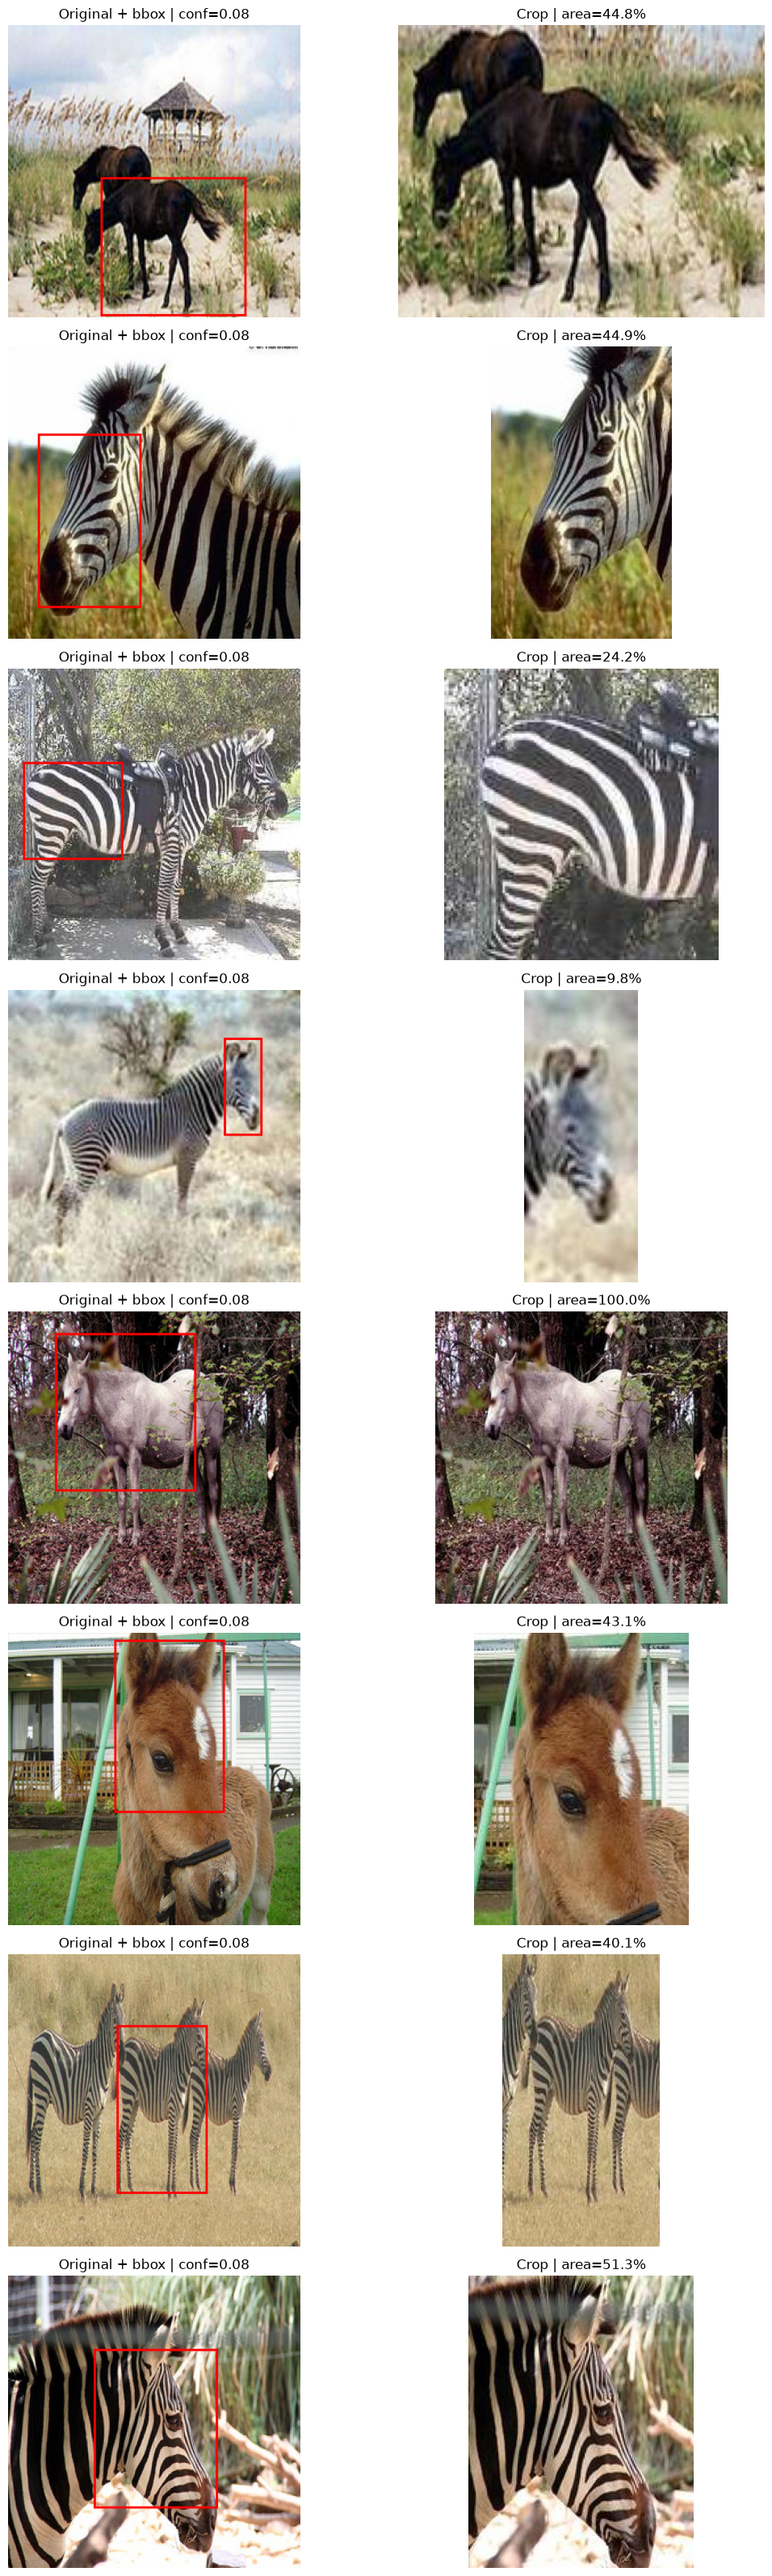

Jumlah gagal deteksi: 525


In [7]:
from PIL import ImageDraw

# Tampilkan hingga 8 hasil deteksi dengan confidence terendah.
detected_samples = (
    focus_df[focus_df["focus_status"] == "detected"]
    .dropna(subset=["max_confidence"])
    .sort_values("max_confidence")
    .head(8)
)

if len(detected_samples) > 0:
    fig, axes = plt.subplots(len(detected_samples), 2, figsize=(12, 4 * len(detected_samples)))
    if len(detected_samples) == 1:
        axes = np.array([axes])

    for row_idx, (_, row) in enumerate(detected_samples.iterrows()):
        with Image.open(row["source_path"]) as im:
            original = ImageOps.exif_transpose(im).convert("RGB")
        draw = ImageDraw.Draw(original)
        box = (
            int(row["bbox_x1"]), int(row["bbox_y1"]),
            int(row["bbox_x2"]), int(row["bbox_y2"])
        )
        draw.rectangle(box, outline="red", width=max(2, original.width // 300))

        with Image.open(row["focused_path"]) as im:
            crop = im.convert("RGB")

        axes[row_idx, 0].imshow(original)
        axes[row_idx, 0].set_title(
            f'Original + bbox | conf={row["max_confidence"]:.2f}'
        )
        axes[row_idx, 1].imshow(crop)
        axes[row_idx, 1].set_title(
            f'Crop | area={row["crop_area_pct"]:.1f}%'
        )
        axes[row_idx, 0].axis("off")
        axes[row_idx, 1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Belum ada gambar yang berhasil dideteksi.")

print("Jumlah gagal deteksi:", (focus_df["focus_status"] == "no_detection").sum())


## 5. Blur detection pada area objek

Blur score dihitung di **bounding box objek pada gambar asli**, bukan seluruh crop. Jadi background yang tajam tidak terlalu memengaruhi penilaian blur objek.

Laplacian Variance tetap merupakan indikator sederhana. Nilainya dipengaruhi resolusi dan tekstur, jadi `BLUR_THRESHOLD` harus ditentukan setelah melihat sampel hasil dataset ini. ROI sangat kecil dimasukkan ke review manual.

In [8]:
def calculate_object_blur_score(image_path, bbox, min_size=MIN_BLUR_ROI_SIZE):
    image = cv2.imread(str(image_path))
    if image is None or bbox is None:
        return None, 0, 0

    x1, y1, x2, y2 = [int(round(v)) for v in bbox]
    height, width = image.shape[:2]
    x1 = max(0, min(x1, width - 1))
    y1 = max(0, min(y1, height - 1))
    x2 = max(x1 + 1, min(x2, width))
    y2 = max(y1 + 1, min(y2, height))

    roi = image[y1:y2, x1:x2]
    roi_h, roi_w = roi.shape[:2]

    if roi_w < min_size or roi_h < min_size:
        return None, roi_w, roi_h

    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    score = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    return score, roi_w, roi_h


blur_records = []

for _, row in focus_df.iterrows():
    record = row.to_dict()

    if row["focus_status"] != "detected":
        record["blur_score"] = None
        record["blur_roi_width"] = None
        record["blur_roi_height"] = None
        blur_records.append(record)
        continue

    bbox = (
        row["bbox_x1"], row["bbox_y1"],
        row["bbox_x2"], row["bbox_y2"]
    )
    score, roi_w, roi_h = calculate_object_blur_score(
        row["source_path"], bbox
    )

    record["blur_score"] = score
    record["blur_roi_width"] = roi_w
    record["blur_roi_height"] = roi_h
    blur_records.append(record)

blur_df = pd.DataFrame(blur_records)
blur_df.to_csv("blur_report_v2.csv", index=False)

print("\nRingkasan blur score per folder:")
print(
    blur_df[blur_df["blur_score"].notna()]
    .groupby("folder")["blur_score"].describe()
)
print("\nLaporan: blur_report_v2.csv")



Ringkasan blur score per folder:
         count         mean          std         min          25%  \
folder                                                              
testA     89.0  3031.193175  1970.738887  277.360708  1641.072903   
testB    118.0  9410.826730  6313.834568  560.373452  4486.442382   
trainA   810.0  2904.690957  1861.582074  150.457934  1589.097269   
trainB  1110.0  9024.659124  5495.104997  477.466896  4978.376817   

                50%           75%           max  
folder                                           
testA   2526.730489   4210.617613  10272.200530  
testB   7957.354067  13596.003765  25419.145461  
trainA  2517.824865   3763.829017  12093.895503  
trainB  8048.404370  11975.604301  38045.243925  

Laporan: blur_report_v2.csv


## 6. Inspeksi gambar dengan blur score terendah

Periksa objeknya, bukan hanya keseluruhan foto. Blur score rendah tidak selalu berarti blur; tekstur bulu, pencahayaan, dan ukuran ROI juga berpengaruh.

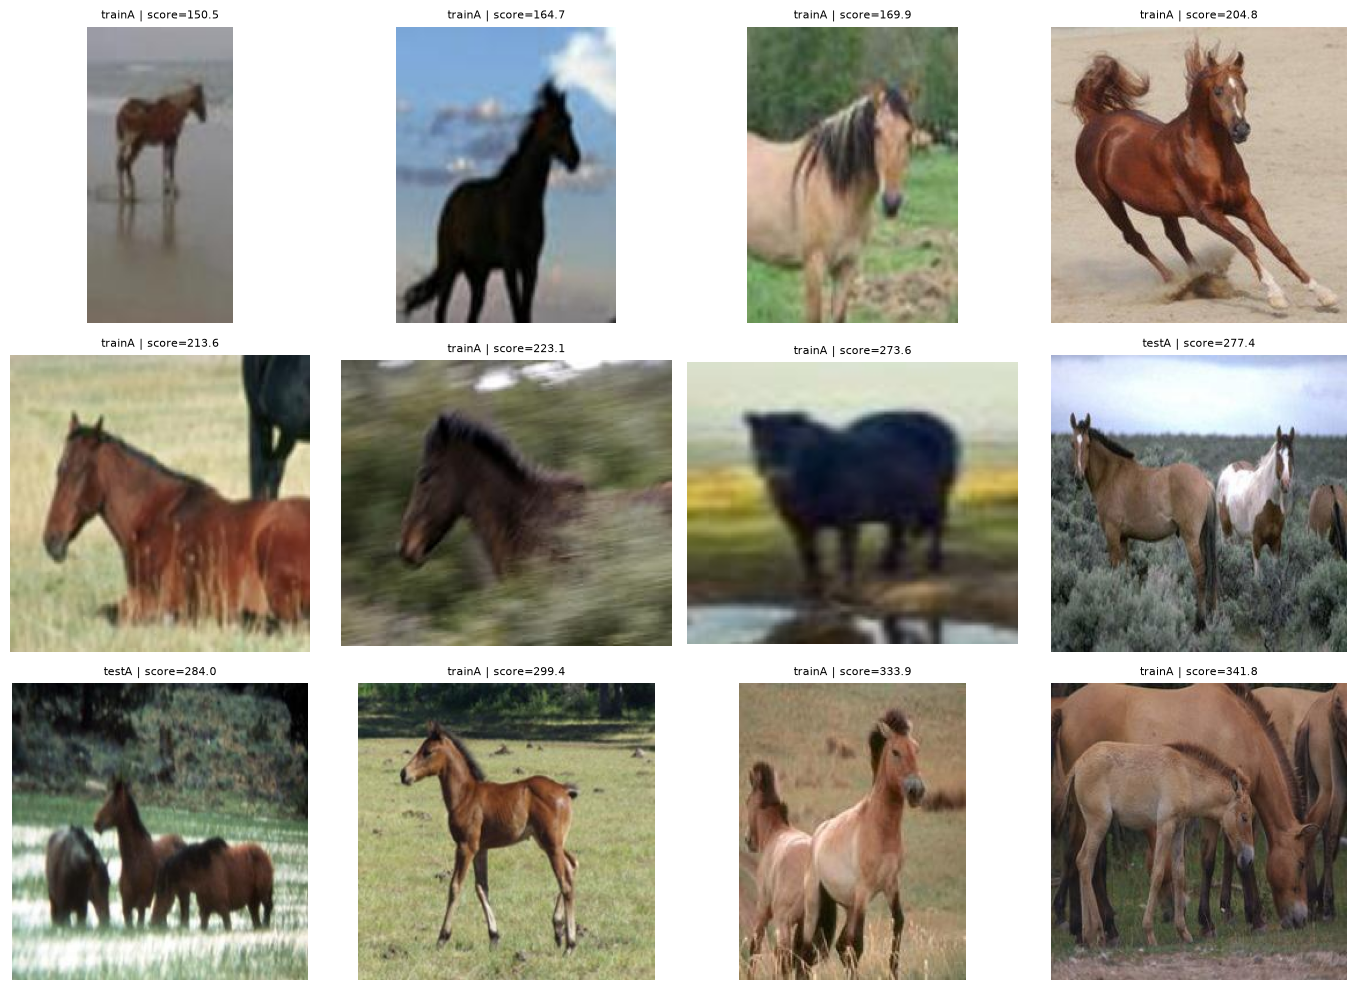

In [9]:
lowest_scores = (
    blur_df.dropna(subset=["blur_score"])
    .sort_values("blur_score")
    .head(12)
)

if len(lowest_scores) > 0:
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    for ax, (_, row) in zip(axes.flat, lowest_scores.iterrows()):
        with Image.open(row["focused_path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(
            f'{row["folder"]} | score={row["blur_score"]:.1f}',
            fontsize=8
        )
        ax.axis("off")

    for ax in axes.flat[len(lowest_scores):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Belum ada blur score yang dapat dihitung.")


## 7. Cleaning: clean, blur review, dan focus review

Aturan:
- `detected` dan blur score ≥ threshold → `data_cleaned_v2/`.
- `detected` dan blur score < threshold atau ROI terlalu kecil → `blur_review_v2/`.
- `no_detection` / `unreadable` → `focus_review_v2/`.

File asli tetap aman di `data/`. Periksa folder review sebelum memutuskan membuang gambar.

In [10]:
def standardize_image(image, size=256):

    image = image.convert("RGB")

    # Resize dengan mempertahankan rasio aspek
    resized = ImageOps.contain(
        image,
        (size, size),
        method=Image.Resampling.LANCZOS
    )

    # Membuat kanvas 256x256
    canvas = Image.new(
        "RGB",
        (size, size),
        (127, 127, 127)
    )

    # Menempatkan gambar di tengah kanvas
    x = (size - resized.width) // 2
    y = (size - resized.height) // 2

    canvas.paste(resized, (x, y))

    return canvas


# Cleaning dan penyimpanan dataset
for _, row in blur_df.iterrows():

    if pd.isna(row["focused_path"]):
        continue

    source = Path(row["focused_path"])

    if not source.exists():
        continue

    relative_path = source.relative_to(FOCUSED_DIR)
    score = row["blur_score"]

    # Menentukan status cleaning
    if row["focus_status"] != "detected":

        destination = FOCUS_REVIEW_DIR / relative_path
        cleaning_status = "focus_review"

    elif pd.isna(score) or score < BLUR_THRESHOLD:

        destination = BLUR_REVIEW_DIR / relative_path
        cleaning_status = "blur_review"

    else:

        destination = CLEAN_DIR / relative_path
        cleaning_status = "cleaned"

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # Hanya gambar yang lolos cleaning
    # disimpan dalam ukuran standar 256x256.
    if cleaning_status == "cleaned":

        with Image.open(source) as img:

            final_image = standardize_image(
                img,
                IMAGE_SIZE
            )

            final_image.save(destination)

    else:

        # Gambar review tetap disimpan dalam ukuran aslinya
        shutil.copy2(source, destination)

    blur_df.loc[
        blur_df.index == row.name,
        "cleaning_status"
    ] = cleaning_status


# Simpan laporan
blur_df.to_csv(
    "preprocessing_report_v2.csv",
    index=False
)

print("Cleaning selesai.")

print("\nRingkasan:")
print(blur_df.groupby(["folder", "cleaning_status"]).size())

print("\nClean:", CLEAN_DIR)
print("Review blur:", BLUR_REVIEW_DIR)
print("Review fokus:", FOCUS_REVIEW_DIR)
print("Report: preprocessing_report_v2.csv")


Cleaning selesai.

Ringkasan:
folder  cleaning_status
testA   cleaned              89
        focus_review         31
testB   cleaned             118
        focus_review         22
trainA  blur_review           9
        cleaned             810
        focus_review        248
trainB  cleaned            1110
        focus_review        224
dtype: int64

Clean: data_cleaned_v2
Review blur: blur_review_v2
Review fokus: focus_review_v2
Report: preprocessing_report_v2.csv


## 8. Resize dengan padding, RGB, tensor, normalisasi

Hasil crop tidak diregangkan. Gambar diperkecil agar muat di kanvas 256×256, lalu ditambah padding. Padding abu-abu menjadi nilai sekitar nol setelah normalisasi `[-1, 1]`.

In [11]:
class ResizeWithPadding:
    def __init__(self, size=256, fill=(127, 127, 127)):
        self.size = size
        self.fill = fill

    def __call__(self, image):
        image = image.convert("RGB")
        resized = ImageOps.contain(
            image,
            (self.size, self.size),
            method=Image.Resampling.LANCZOS
        )
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        x = (self.size - resized.width) // 2
        y = (self.size - resized.height) // 2
        canvas.paste(resized, (x, y))
        return canvas


train_transform = transforms.Compose([
    ResizeWithPadding(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

test_transform = transforms.Compose([
    ResizeWithPadding(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

## 9. Dataset dan DataLoader CycleGAN

DataLoader hanya membaca `data_cleaned_v2/`. Pastikan gambar di folder review sudah diperiksa manual sebelum dipindahkan ke folder clean.

In [12]:
class HorseZebraDataset(Dataset):
    def __init__(self, root, split="train"):
        self.root = Path(root)
        self.split = split
        self.transform = train_transform if split == "train" else test_transform

        self.horses = sorted(
            p for p in (self.root / f"{split}A").rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )
        self.zebras = sorted(
            p for p in (self.root / f"{split}B").rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )

        if not self.horses or not self.zebras:
            raise ValueError(
                f"Folder domain kosong: {self.root / f'{split}A'} "
                f"atau {self.root / f'{split}B'}"
            )

    def __len__(self):
        return max(len(self.horses), len(self.zebras))

    def __getitem__(self, index):
        horse_path = self.horses[index % len(self.horses)]
        zebra_path = (
            random.choice(self.zebras) if self.split == "train"
            else self.zebras[index % len(self.zebras)]
        )

        with Image.open(horse_path) as img:
            horse = self.transform(ImageOps.exif_transpose(img).copy())
        with Image.open(zebra_path) as img:
            zebra = self.transform(ImageOps.exif_transpose(img).copy())

        return {"A": horse, "B": zebra}


train_dataset = HorseZebraDataset(CLEAN_DIR, split="train")
test_dataset = HorseZebraDataset(CLEAN_DIR, split="test")

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print("Train samples per epoch:", len(train_dataset))
print("Test samples per epoch :", len(test_dataset))


Train samples per epoch: 1110
Test samples per epoch : 118


In [13]:
batch = next(iter(train_loader))
horse = batch["A"]
zebra = batch["B"]

print("Horse shape:", horse.shape)
print("Zebra shape:", zebra.shape)
print("Horse range:", horse.min().item(), horse.max().item())
print("Zebra range:", zebra.min().item(), zebra.max().item())

assert horse.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert zebra.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert horse.min() >= -1 and horse.max() <= 1
assert zebra.min() >= -1 and zebra.max() <= 1

print("Batch berhasil divalidasi.")


Horse shape: torch.Size([1, 3, 256, 256])
Zebra shape: torch.Size([1, 3, 256, 256])
Horse range: -1.0 1.0
Zebra range: -1.0 1.0
Batch berhasil divalidasi.


In [14]:
from collections import Counter

size_counts = Counter()

for folder in FOLDERS:

    folder_path = CLEAN_DIR / folder

    for path in folder_path.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        with Image.open(path) as img:
            size_counts[img.size] += 1

print("Distribusi ukuran gambar:")

for size, count in size_counts.items():
    print(size, ":", count, "gambar")

assert len(size_counts) == 1, \
    "Masih ada gambar dengan ukuran berbeda!"

assert (IMAGE_SIZE, IMAGE_SIZE) in size_counts, \
    "Ukuran gambar belum sesuai konfigurasi!"

print("Semua gambar final memiliki ukuran yang sama.")

Distribusi ukuran gambar:
(256, 256) : 2127 gambar
Semua gambar final memiliki ukuran yang sama.


## Catatan penting dan batasan

1. Jika objek masih tidak terdeteksi, periksa `focus_review_v2/` dan `focus_report_v2.csv`. Detector pretrained tetap bisa gagal pada objek yang sangat kecil, tertutup, atau foto yang berbeda dari data latih COCO.
2. Tiled inference membantu objek kecil pada foto beresolusi besar. Jika foto sumber memang beresolusi rendah, tile tidak dapat menciptakan detail yang tidak ada.
3. Confidence rendah (`0.08`) membantu recall tetapi dapat menambah false positive. Karena itu audit visual bounding box tetap wajib.
4. Crop mengikuti bounding box + padding; rasio crop bisa berbeda dari rasio foto penuh. Ini disengaja agar hewan lebih besar di dalam crop. Piksel tidak diregangkan. Tahap resize memakai padding untuk input persegi CycleGAN.
5. Blur yang sudah ada tidak dapat diperbaiki oleh cropping. Gambar yang buram masuk `blur_review_v2/`; jangan menganggap crop membuatnya tajam.
6. Laplacian Variance adalah indikator sederhana, bukan ukuran kualitas sempurna. Kalibrasikan threshold berdasarkan sampel dari horse dan zebra.
7. Jika sebagian besar deteksi masih keliru, solusi yang lebih tepat adalah fine-tuning detector dengan contoh horse/zebra dari dataset sendiri atau anotasi bounding box manual.
8. Dataset asli dan `metadata.csv` tidak diubah.